## Lab 2 — What Did the Campaign Deliver?
Name: Maksym Dorofeiev Andriyovych | Group: KM-41

## Setup

In [12]:
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = kagglehub.dataset_download('shkarupylomaxim/adtech-lab1-tv-panel/versions/3')
programs = pd.read_parquet(f'{DATA}/programs.parquet')
viewings = pd.read_parquet(f'{DATA}/viewings.parquet')
daily_weights = pd.read_parquet(f'{DATA}/daily_weights.parquet')
viewer_attributes = pd.read_parquet(f'{DATA}/viewer_attributes.parquet')
attributes = pd.read_parquet(f'{DATA}/attributes.parquet')
commercials = pd.read_parquet(f'{DATA}/commercials.parquet')
rate_card = pd.read_parquet(f'{DATA}/rate_card.parquet')

## Task 1.1 — Size

In [13]:
print('Spots:', len(commercials))
print('Pods:', commercials['pod_id'].nunique())
print('Brands:', commercials['brand'].nunique())
print('Categories:', commercials['category'].nunique())

brand_a = commercials[commercials['brand'] == 'BRAND_A']
print('BRAND_A spots:', len(brand_a))

brand_a_by_net = (brand_a.groupby('network_code')['ad_airing_id'].count().rename('spots').sort_values(ascending=False).to_frame())
display(brand_a_by_net)

Spots: 167720
Pods: 22359
Brands: 95
Categories: 14
BRAND_A spots: 300


,spots
network_code,
FNC,40
HGTV,39
FX,38
HIST,37
FOOD,33
BRAVO,33
ABC,29
CBS,22
NBC,16


## Task 1.2 — Ad load

In [14]:
commercials['clock_hour'] = pd.to_datetime(commercials['start_ts']).dt.floor('h')

ad_load = (
    commercials.groupby(['network_code', 'clock_hour'])['length_sec']
    .sum()
    .div(60)
    .groupby('network_code')
    .mean()
    .round(1)
    .sort_values(ascending=False)
    .rename('ad_minutes_per_hour')
    .to_frame()
)
display(ad_load)
print('Heaviest ad load:', ad_load.index[0])

,ad_minutes_per_hour
network_code,
FNC,15.6
BRAVO,13.4
HGTV,13.3
HIST,13.2
FOOD,13.1
FX,12.9
CBS,12.1
ABC,11.8
FOX,11.8


Heaviest ad load: FNC


**Answer**: Broadcast networks (CBS, NBC, ABC, FOX) hand parts of the broadcast day (such as local news, daytime syndication, and late fringe) back to their local affiliate stations, where ad breaks are sold locally rather than nationally. In addition, hours containing paid programming or special uninterrupted broadcasts like the vice-presidential debate have no national commercials in the ad log

## Task 1.3 — Price everything

In [15]:
def to_bcast_min(t_str):
    h, m = map(int, str(t_str).split(':'))
    return h * 60 + m - 360

spots = commercials.merge(
    programs[['telecast_id', 'program_name']].drop_duplicates('telecast_id'),
    on='telecast_id',
    how='left'
)

# Program rows (sports / special programs) win first
rc_prog = rate_card[rate_card['program_name'].fillna('') != ''][['network_code', 'program_name', 'daypart', 'cost_30s_usd']].copy()
rc_prog['is_prog_row'] = True

spots = spots.merge(rc_prog, on=['network_code', 'program_name'], how='left')
spots['is_prog_row'] = spots['is_prog_row'].fillna(False)

# Time rows for remaining spots (broadcast clock: start_ts - 6 hours)
bcast_ts = pd.to_datetime(spots['start_ts']) - pd.Timedelta(hours=6)
spots['bday'] = bcast_ts.dt.weekday
spots['bmin'] = bcast_ts.dt.hour * 60 + bcast_ts.dt.minute

rc_time = rate_card[rate_card['program_name'].fillna('') == ''].copy()
rc_time['start_min'] = rc_time['start_time'].apply(to_bcast_min)
rc_time['end_min'] = rc_time['end_time'].apply(to_bcast_min)
rc_time_exp = rc_time.explode('weekdays').rename(columns={'weekdays': 'bday'})
rc_time_exp['bday'] = rc_time_exp['bday'].astype(int)

unmatched = spots[spots['cost_30s_usd'].isna()][['ad_airing_id', 'network_code', 'bday', 'bmin']].merge(
    rc_time_exp[['network_code', 'bday', 'daypart', 'cost_30s_usd', 'start_min', 'end_min']],
    on=['network_code', 'bday'],
    how='left'
)
unmatched = unmatched[(unmatched['bmin'] >= unmatched['start_min']) & (unmatched['bmin'] < unmatched['end_min'])].drop_duplicates('ad_airing_id')

spots['daypart'] = spots['daypart'].fillna(spots['ad_airing_id'].map(unmatched.set_index('ad_airing_id')['daypart']))
spots['cost_30s_usd'] = spots['cost_30s_usd'].fillna(spots['ad_airing_id'].map(unmatched.set_index('ad_airing_id')['cost_30s_usd']))
spots['cost_usd'] = spots['cost_30s_usd'] * (spots['length_sec'] / 30)

print('Spots without a price:', int(spots['cost_usd'].isna().sum()))

net_val = spots.groupby('network_code').agg(
    total_usd=('cost_usd', 'sum'),
    prog_usd=('cost_usd', lambda s: s[spots.loc[s.index, 'is_prog_row']].sum())
)
net_val['value_usd_m'] = (net_val['total_usd'] / 1e6).round(1)
net_val['program_row_share'] = (net_val['prog_usd'] / net_val['total_usd']).round(3)
display(net_val[['value_usd_m', 'program_row_share']].sort_values('value_usd_m', ascending=False))

Spots without a price: 0


,value_usd_m,program_row_share
network_code,,
CBS,818.8,0.230
NBC,724.3,0.342
ABC,708.8,0.432
FOX,696.2,0.835
FNC,315.8,0.000
HGTV,58.1,0.000
FX,42.5,0.000
FOOD,42.1,0.000
HIST,40.1,0.000


## Task 2.1 — Delivery

In [16]:
# Persons (R and L only) and broadcast dates
dw = daily_weights[daily_weights['resp_type'].isin(['R', 'L'])].copy()
dw['bdate'] = pd.to_datetime(dw['broadcast_date']).dt.date
monthly_w = dw.groupby('respondent_id')['weight'].mean()

# Demographics from viewer_attributes (300 = age, 202 = female)
ages = viewer_attributes[viewer_attributes['attr_id'] == 300].set_index('respondent_id')['value'].astype(float)
a18_49_ids = set(ages[(ages >= 18) & (ages <= 49)].index)
female_ids = set(viewer_attributes[viewer_attributes['attr_id'] == 202]['respondent_id'])
w18_34_ids = set(ages[(ages >= 18) & (ages <= 34)].index) & female_ids

# BRAND_A spots and exposures (session start <= spot start < session end)
brand_a_spots = spots[spots['brand'] == 'BRAND_A'].copy()
brand_a_spots['spot_ts'] = pd.to_datetime(brand_a_spots['start_ts'])
brand_a_spots['bdate'] = (brand_a_spots['spot_ts'] - pd.Timedelta(hours=6)).dt.date

v_rl = viewings[viewings['resp_type'].isin(['R', 'L'])][['respondent_id', 'network_code', 'start_ts', 'end_ts']].copy()
v_rl['v_start'] = pd.to_datetime(v_rl['start_ts'])
v_rl['v_end'] = pd.to_datetime(v_rl['end_ts'])

exposures = brand_a_spots[['ad_airing_id', 'network_code', 'spot_ts', 'bdate', 'cost_usd']].merge(
    v_rl[['respondent_id', 'network_code', 'v_start', 'v_end']],
    on='network_code'
)
exposures = exposures[(exposures['v_start'] <= exposures['spot_ts']) & (exposures['spot_ts'] < exposures['v_end'])]
exposures = exposures.drop_duplicates(['ad_airing_id', 'respondent_id'])
exposures = exposures.merge(dw[['respondent_id', 'bdate', 'weight']], on=['respondent_id', 'bdate'], how='left')
exposures['is_a18_49'] = exposures['respondent_id'].isin(a18_49_ids)
exposures['is_w18_34'] = exposures['respondent_id'].isin(w18_34_ids)

# Daily in tab universes
univ_p2_daily = dw.groupby('bdate')['weight'].sum()
univ_a18_49_daily = dw[dw['respondent_id'].isin(a18_49_ids)].groupby('bdate')['weight'].sum()

# Spot level impressions and ratings
spot_imp_p2 = exposures.groupby('ad_airing_id')['weight'].sum()
spot_imp_a18_49 = exposures[exposures['is_a18_49']].groupby('ad_airing_id')['weight'].sum()

brand_a_spots['imp_p2'] = brand_a_spots['ad_airing_id'].map(spot_imp_p2).fillna(0.0)
brand_a_spots['imp_a18_49'] = brand_a_spots['ad_airing_id'].map(spot_imp_a18_49).fillna(0.0)
brand_a_spots['rating_p2'] = brand_a_spots['imp_p2'] / brand_a_spots['bdate'].map(univ_p2_daily) * 100.0
brand_a_spots['rating_a18_49'] = brand_a_spots['imp_a18_49'] / brand_a_spots['bdate'].map(univ_a18_49_daily) * 100.0

# P2+ metrics
p2_imp = brand_a_spots['imp_p2'].sum()
p2_grps = brand_a_spots['rating_p2'].sum()
p2_reach = monthly_w.loc[exposures['respondent_id'].unique()].sum() / monthly_w.sum() * 100.0
p2_freq = p2_grps / p2_reach

# A18-49 metrics
monthly_w_a18_49 = monthly_w[monthly_w.index.isin(a18_49_ids)]
a18_49_imp = brand_a_spots['imp_a18_49'].sum()
a18_49_grps = brand_a_spots['rating_a18_49'].sum()
a18_49_reach = (monthly_w_a18_49.loc[exposures[exposures['is_a18_49']]['respondent_id'].unique()].sum() / monthly_w_a18_49.sum() * 100.0)
a18_49_freq = a18_49_grps / a18_49_reach

print('P2+ impressions (M):', round(p2_imp / 1e6, 1))
print('P2+ GRPs:', round(p2_grps, 1))
print('P2+ reach (%):', round(p2_reach, 1))
print('P2+ average frequency:', round(p2_freq, 1))
print('A18-49 impressions (M):', round(a18_49_imp / 1e6, 1))
print('A18-49 GRPs:', round(a18_49_grps, 1))
print('A18-49 reach (%):', round(a18_49_reach, 1))
print('A18-49 average frequency:', round(a18_49_freq, 1))

P2+ impressions (M): 418.8
P2+ GRPs: 132.0
P2+ reach (%): 43.5
P2+ average frequency: 3.0
A18-49 impressions (M): 81.1
A18-49 GRPs: 60.4
A18-49 reach (%): 30.5
A18-49 average frequency: 2.0


## Task 2.2 — Frequency distribution

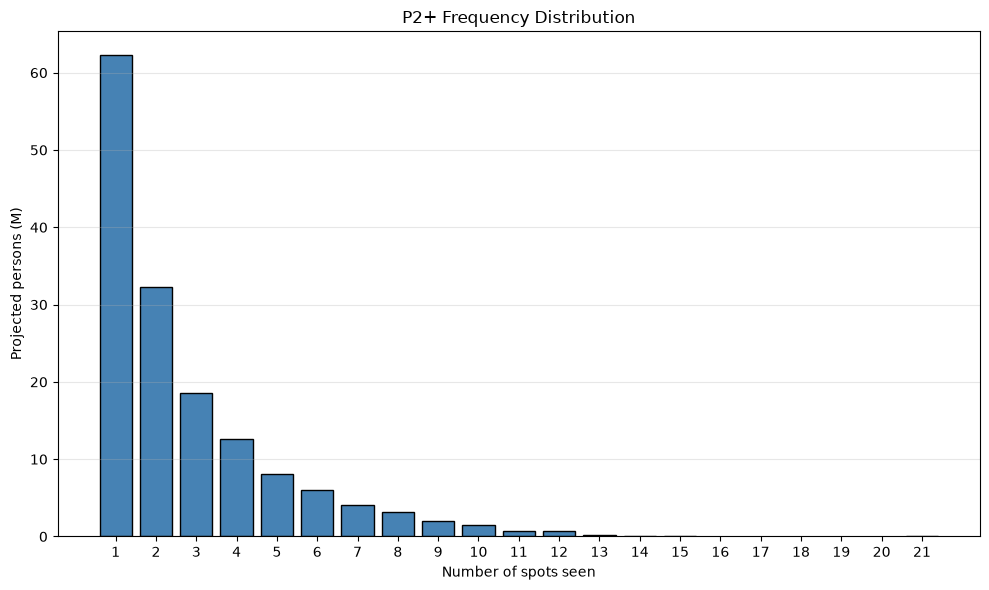

Share of impressions at 5+ exposures: 0.444


In [24]:
person_freq = exposures.groupby('respondent_id')['ad_airing_id'].count().rename('spots_seen').to_frame()
person_freq['monthly_weight'] = monthly_w.loc[person_freq.index]

freq_dist = person_freq.groupby('spots_seen')['monthly_weight'].sum() / 1e6

plt.figure(figsize=(10, 6))
plt.bar(freq_dist.index, freq_dist.values, color='steelblue', edgecolor='black')
plt.xlabel('Number of spots seen')
plt.ylabel('Projected persons (M)')
plt.title('P2+ Frequency Distribution')
plt.xticks(range(1, int(freq_dist.index.max()) + 1))
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

heavy_viewers = set(person_freq[person_freq['spots_seen'] >= 5].index)
share_5plus = exposures[exposures['respondent_id'].isin(heavy_viewers)]['weight'].sum() / p2_imp
print('Share of impressions at 5+ exposures:', round(share_5plus, 3))

**Answer:** No, the average frequency is not a fair summary on its own because the exposure distribution is heavily right-skewed: most reached viewers see only 1 to 2 spots, whereas a relatively small group of heavy viewers (5+ exposures) absorbs a large share of total impressions and pulls the average up

## Task 2.3 — On target?

In [18]:
target_share = a18_49_imp / p2_imp
print('Share of impressions on A18-49:', round(target_share, 3))

net_target = brand_a_spots.groupby('network_code')[['imp_p2', 'imp_a18_49']].sum()
net_target['a18_49_share'] = (net_target['imp_a18_49'] / net_target['imp_p2']).round(3)
display(net_target[['a18_49_share']].sort_values('a18_49_share', ascending=False))

Share of impressions on A18-49: 0.194


,a18_49_share
network_code,
FX,0.651
BRAVO,0.554
FOOD,0.316
HGTV,0.306
FOX,0.242
HIST,0.202
NBC,0.189
ABC,0.180
CBS,0.154


**Answer:** The campaign under-delivered against its A18-49 target compared with the 42% population benchmark (only about a third of impressions landed on A18-49). Linear TV viewers skew older overall, and networks such as FNC, HIST, HGTV, and CBS have particularly old audiences (low A18-49 shares), whereas entertainment/lifestyle networks like BRAVO, FX, and FOX deliver a higher concentration of A18-49 viewers

## Task 3.1 — Cost

In [19]:
campaign_cost = brand_a_spots['cost_usd'].sum()
p2_cpm = campaign_cost / (p2_imp / 1000.0)
p2_cpp = campaign_cost / p2_grps
a18_49_cpm = campaign_cost / (a18_49_imp / 1000.0)
a18_49_cpp = campaign_cost / a18_49_grps

print('Campaign cost (USD):', round(campaign_cost))
print('P2+ CPM (USD):', round(p2_cpm, 2))
print('P2+ CPP (USD):', round(p2_cpp))
print('A18-49 CPM (USD):', round(a18_49_cpm, 2))
print('A18-49 CPP (USD):', round(a18_49_cpp))

Campaign cost (USD): 7420270
P2+ CPM (USD): 17.72
P2+ CPP (USD): 56221
A18-49 CPM (USD): 91.53
A18-49 CPP (USD): 122836


## Task 3.2 — By network

In [20]:
by_net = brand_a_spots.groupby('network_code').agg(
    spots=('ad_airing_id', 'count'),
    cost_usd=('cost_usd', 'sum'),
    imp_p2=('imp_p2', 'sum'),
    imp_a18_49=('imp_a18_49', 'sum')
)
by_net['cost_usd'] = by_net['cost_usd'].round(0).astype(int)
by_net['p2_impressions_m'] = (by_net['imp_p2'] / 1e6).round(1)
by_net['a18_49_impressions_m'] = (by_net['imp_a18_49'] / 1e6).round(1)
by_net['p2_cpm_usd'] = (by_net['cost_usd'] / (by_net['imp_p2'] / 1000.0)).round(2)
by_net['a18_49_cpm_usd'] = (by_net['cost_usd'] / (by_net['imp_a18_49'] / 1000.0)).round(2)

display(by_net[['spots', 'cost_usd', 'p2_impressions_m', 'a18_49_impressions_m', 'p2_cpm_usd', 'a18_49_cpm_usd']].sort_values('cost_usd', ascending=False))

,spots,cost_usd,p2_impressions_m,a18_49_impressions_m,p2_cpm_usd,a18_49_cpm_usd
network_code,,,,,,
FOX,13,2434700,76.3,18.4,31.93,132.03
ABC,29,1625700,94.2,17.0,17.26,95.69
CBS,22,1488700,89.0,13.7,16.73,108.72
NBC,16,796800,41.4,7.8,19.23,101.72
FNC,40,526300,57.8,2.7,9.11,193.70
HGTV,39,230000,24.7,7.6,9.33,30.45
FOOD,33,96620,9.5,3.0,10.19,32.29
FX,38,92200,8.5,5.6,10.82,16.61
HIST,37,79640,12.3,2.5,6.46,32.05


**Answer:** Most of the budget went to the four major broadcast networks (NBC, CBS, ABC, FOX), driven by expensive primetime and live sports rate cards. The cheapest networks for reaching the A18-49 target (lowest A18-49 CPM) were the smaller targeted cable networks (such as FX, BRAVO, and FOOD), while older-skewing or high-premium networks had the highest target CPM

## Task 3.3 — Guarantee

In [21]:
guarantee_met = bool(p2_grps >= 150.0)
make_good_grps = max(0.0, 150.0 - p2_grps)
make_good_value = make_good_grps * p2_cpp

print('Guarantee met:', guarantee_met)
print('Make-good GRPs owed:', round(make_good_grps, 1))
print('Value of make-goods (USD):', round(make_good_value))

Guarantee met: False
Make-good GRPs owed: 18.0
Value of make-goods (USD): 1012869


## Task 4 — Do networks add up?

In [22]:
BIG_NETS = {'CBS', 'NBC', 'ABC', 'FOX', 'FNC'}
SMALL_NETS = {'FX', 'BRAVO', 'HGTV', 'FOOD', 'HIST'}

big_ids = set(exposures[exposures['network_code'].isin(BIG_NETS)]['respondent_id'])
small_ids = set(exposures[exposures['network_code'].isin(SMALL_NETS)]['respondent_id'])
whole_ids = big_ids | small_ids
overlap_ids = big_ids & small_ids

total_p2_w = monthly_w.sum()
reach_big = monthly_w.loc[list(big_ids)].sum() / total_p2_w * 100.0
reach_small = monthly_w.loc[list(small_ids)].sum() / total_p2_w * 100.0
reach_whole = monthly_w.loc[list(whole_ids)].sum() / total_p2_w * 100.0
overlap_pct = monthly_w.loc[list(overlap_ids)].sum() / total_p2_w * 100.0
overlap_indep = (reach_big * reach_small) / 100.0

reach_added_small = reach_whole - reach_big
cost_big = brand_a_spots[brand_a_spots['network_code'].isin(BIG_NETS)]['cost_usd'].sum()
cost_small = brand_a_spots[brand_a_spots['network_code'].isin(SMALL_NETS)]['cost_usd'].sum()

cost_per_added_small = cost_small / reach_added_small
cost_per_pt_big = cost_big / reach_big

print('Reach, big networks (%):', round(reach_big, 1))
print('Reach, small networks (%):', round(reach_small, 1))
print('Reach, whole campaign (%):', round(reach_whole, 1))
print('Overlap (%):', round(overlap_pct, 1))
print('Overlap if independent (%):', round(overlap_indep, 1))
print('Reach added by small networks (points):', round(reach_added_small, 1))
print('Cost per added reach point, small (USD):', round(cost_per_added_small))
print('Cost per reach point, big (USD):', round(cost_per_pt_big))

Reach, big networks (%): 39.8
Reach, small networks (%): 12.4
Reach, whole campaign (%): 43.5
Overlap (%): 8.7
Overlap if independent (%): 4.9
Reach added by small networks (points): 3.7
Cost per added reach point, small (USD): 148706
Cost per reach point, big (USD): 172456


**Answer:** Reach does not add across networks because many viewers watch both big and small networks, so those duplicated viewers are counted only once in total campaign reach. The observed overlap is higher than the independent expectation because TV viewing is positively correlated across networks (heavy TV viewers watch multiple channels, making small-network viewers more likely than average to also be reached on big networks). Even with audience duplication, the small networks were much cheaper per spot, so their cost per incremental reach point remained competitive compared with the high cost per reach point on the big networks

## Task 5 — How sure are we?

In [23]:
panelists_per_spot = exposures.groupby('ad_airing_id')['respondent_id'].nunique()
w18_34_per_spot = exposures[exposures['is_w18_34']].groupby('ad_airing_id')['respondent_id'].nunique()
n_intab_daily = dw.groupby('bdate')['respondent_id'].nunique()

brand_a_spots['panelists'] = brand_a_spots['ad_airing_id'].map(panelists_per_spot).fillna(0).astype(int)
brand_a_spots['w18_34_panelists'] = brand_a_spots['ad_airing_id'].map(w18_34_per_spot).fillna(0).astype(int)
brand_a_spots['n_intab'] = brand_a_spots['bdate'].map(n_intab_daily)

p_frac = brand_a_spots['rating_p2'] / 100.0
brand_a_spots['se'] = np.sqrt(p_frac * (1.0 - p_frac) / brand_a_spots['n_intab']) * 100.0
brand_a_spots['rel_se'] = np.where(brand_a_spots['rating_p2'] > 0, brand_a_spots['se'] / brand_a_spots['rating_p2'], np.nan)

task5_table = brand_a_spots.groupby('network_code').agg(
    median_panelists=('panelists', 'median'),
    median_rel_se=('rel_se', 'median')
)
task5_table['median_rel_se'] = task5_table['median_rel_se'].round(3)
display(task5_table.sort_values('median_panelists', ascending=False))

print('Spots seen by no panelist:', int((brand_a_spots['panelists'] == 0).sum()))
print(
    'Median relative SE, big networks:',
    round(brand_a_spots[brand_a_spots['network_code'].isin(BIG_NETS)]['rel_se'].median(), 3)
)
print(
    'Median relative SE, small networks:',
    round(brand_a_spots[brand_a_spots['network_code'].isin(SMALL_NETS)]['rel_se'].median(), 3)
)
print('W18-34 zero-cell spots:', int((brand_a_spots['w18_34_panelists'] == 0).sum()))

,median_panelists,median_rel_se
network_code,,
FOX,145.0,0.080
CBS,69.0,0.113
NBC,68.5,0.115
ABC,57.0,0.123
FNC,31.0,0.164
HGTV,11.0,0.301
FX,5.5,0.423
FOOD,5.0,0.423
HIST,5.0,0.460


Spots seen by no panelist: 10
Median relative SE, big networks: 0.122
Median relative SE, small networks: 0.417
W18-34 zero-cell spots: 171


**Answer:** A zero rating in the panel does not mean literally nobody in the US watched the spot; it means the true audience on a small network or niche daypart was too small for a panel of a few thousand people to capture even a single viewer (sampling noise / zero-cell problem). If the client asked for spot-by-spot W18-34 ratings, we should advise against using single-spot estimates because most spots have zero or near-zero W18-34 panelists and huge relative standard errors; instead, W18-34 delivery should only be reported aggregated across the full campaign, by network, or by broad daypart